# Semantic Search for Research Papers: Keyword vs Dense vs Hybrid Retrieval

**MAAI 902 – Task 2, NLP Solution Design** · _Your name, student ID_

This notebook runs every experiment for the report:

| Section | What it produces | Report section |
|---|---|---|
| 0 | Setup | – |
| 1 | Dataset statistics and examples | Data & pre-processing |
| 2 | Pre-processing illustration (lexical vs neural input) | Data & pre-processing |
| 3 | BM25 keyword baseline + pre-processing ablation | Design / Results |
| 4 | Dense retrieval with two embedding models (+ query-prefix ablation) | Design / Results |
| 5 | Hybrid retrieval (Reciprocal Rank Fusion), optional re-ranker | Design / Results |
| 6 | Main results table, charts, latency | Results |
| 7 | Error analysis: where keyword search wins and where semantic search wins | Results / Discussion |
| 8 | *Optional* cited-answer generation + manual check sheet | Design / Ethics |
| 9 | Save everything for the report and repo | – |

**Runtime:** Colab → Runtime → Change runtime type → **T4 GPU** (embedding 5k abstracts takes about 1 minute on GPU; on CPU it is slower but still works).

## 0. Setup
**What this does:** gets the project code into Colab, installs the libraries, and imports the project package `sps` (in `src/sps/`).

Choose **one** way to get the code:
- **A (recommended):** push the project folder to your GitHub and put the URL in `REPO_URL`.
- **B:** leave `REPO_URL` empty and upload `task2-semantic-search.zip` when asked.

In [ ]:
import os, sys, zipfile

REPO_URL = ""   # e.g. "https://github.com/<your-username>/semantic-paper-search.git"

if not os.path.exists("src/sps"):
    if REPO_URL:
        !git clone -q {REPO_URL} project
    else:
        from google.colab import files
        uploaded = files.upload()               # choose task2-semantic-search.zip
        zipfile.ZipFile(next(iter(uploaded))).extractall("project")
    root = next(os.path.join(d) for d, _, f in os.walk("project") if "requirements.txt" in f)
    os.chdir(root)
print("Working directory:", os.getcwd())

Saving task2-semantic-search.zip to task2-semantic-search.zip
Working directory: /content/project/task2-semantic-search


In [ ]:
!pip -q install -r requirements.txt

In [ ]:
import os, sys, json, time, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch

sys.path.insert(0, "src")
from sps import load_scifact, BM25Preprocessor, BM25Retriever, DenseRetriever, HybridRetriever, CrossEncoderReranker
from sps.evaluate import run_retriever, evaluate_run, per_query_scores

random.seed(42); np.random.seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("results", exist_ok=True); os.makedirs("cache", exist_ok=True)
pd.set_option("display.max_colwidth", 160)
print("Device:", DEVICE)

Device: cuda


## 1. Data: BEIR SciFact
**What this does:** downloads the three parts of the benchmark from Hugging Face:
- **corpus**: 5,183 scientific abstracts (title + text), the collection we search;
- **queries**: expert-written scientific claims; we use the **300 test claims**;
- **qrels** (relevance labels): for each test claim, which abstract(s) are relevant.

Because the labels already exist, evaluation needs no manual annotation. Note the **~1.1 relevant documents per query**: Precision@10 can never be much above 0.1, so the main metric is nDCG@10, with Recall@k and MRR.

In [ ]:
corpus = load_scifact("test")
texts = corpus.all_full_texts()
pd.Series(corpus.stats(), name="SciFact (test)").to_frame()

README.md:   0%|          | 0.00/10.4k [00:00<?, ?B/s]

corpus/corpus-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 4.47MB            

corpus/corpus-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating corpus split:   0%|          | 0/5183 [00:00<?, ? examples/s]

queries/queries-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 65.0kB            

...

train.tsv:   0%|          | 0.00/14.5k [00:00<?, ?B/s]

test.tsv:   0%|          | 0.00/5.39k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/919 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/339 [00:00<?, ? examples/s]

,SciFact (test)
documents,5183.00
avg words per document,214.60
test queries,300.00
avg words per query,12.50
avg relevant docs per query,1.13


In [ ]:
qid = list(corpus.queries)[0]
idx = corpus.index_of()
print("Example query (claim):", corpus.queries[qid])
for did in corpus.qrels[qid]:
    i = idx[did]
    print("\nRelevant abstract:", corpus.titles[i])
    print(corpus.texts[i][:500], "...")

Example query (claim): 0-dimensional biomaterials show inductive properties.

Relevant abstract: New opportunities: the use of nanotechnologies to manipulate and track stem cells.
Nanotechnologies are emerging platforms that could be useful in measuring, understanding, and manipulating stem cells. Examples include magnetic nanoparticles and quantum dots for stem cell labeling and in vivo tracking; nanoparticles, carbon nanotubes, and polyplexes for the intracellular delivery of genes/oligonucleotides and protein/peptides; and engineered nanometer-scale scaffolds for stem cell differentiation and transplantation. This review examines the use of nanotechnologies for stem ce ...


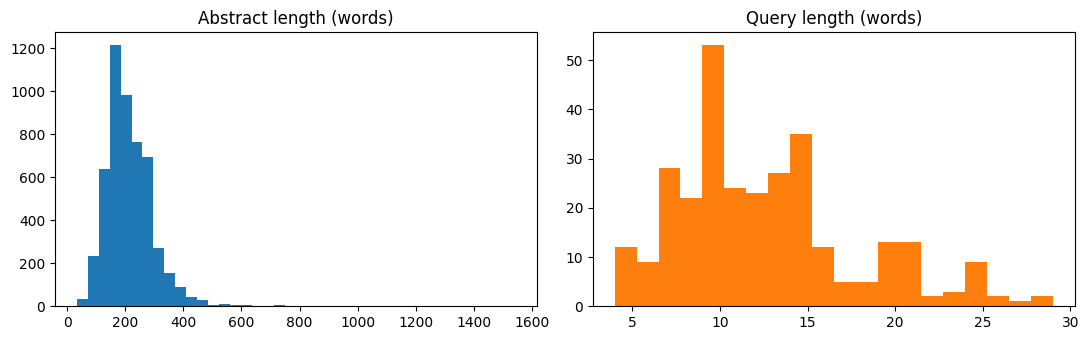

Abstracts longer than ~400 words (may exceed 512 tokens for the encoder): 128


In [ ]:
doc_len = [len(t.split()) for t in texts]
q_len = [len(q.split()) for q in corpus.queries.values()]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(doc_len, bins=40); ax[0].set_title("Abstract length (words)")
ax[1].hist(q_len, bins=20, color="C1"); ax[1].set_title("Query length (words)")
plt.tight_layout(); plt.savefig("results/data_lengths.png", dpi=150); plt.show()
print(f"Abstracts longer than ~400 words (may exceed 512 tokens for the encoder): {sum(l > 400 for l in doc_len)}")

## 2. Pre-processing: lexical vs neural input
**Why two pipelines:** BM25 matches exact terms, so normalising words helps it (lowercase, remove stop-words, stem *"treatments"* → *"treatment"*). Transformer encoders were trained on natural sentences and have their own sub-word tokenizer, so they get the **original text** (only whitespace cleaned). Stemming would destroy information they rely on.

In [ ]:
sample = corpus.queries[qid]
for name, pre in [("raw tokens", BM25Preprocessor(False, False)),
                  ("+ stop-words removed", BM25Preprocessor(True, False)),
                  ("+ Porter stemming", BM25Preprocessor(True, True))]:
    print(f"{name:22s}", pre(sample))

raw tokens             ['0-dimensional', 'biomaterials', 'show', 'inductive', 'properties']
+ stop-words removed   ['0-dimensional', 'biomaterials', 'inductive', 'properties']
+ Porter stemming      ['0-dimension', 'biomateri', 'induct', 'properti']


## 3. BM25 keyword baseline
**What this does:** indexes all abstracts with Okapi BM25 (`rank_bm25`, k1=1.5, b=0.75) and searches the 300 test claims. The **ablation** checks how much each pre-processing step matters.

In [ ]:
RUNS, RESULTS = {}, {}

def evaluate(key, retriever, group):
    run, ms = run_retriever(retriever, corpus, k=100)
    RUNS[key] = run
    RESULTS[key] = {"group": group, "method": retriever.name, **evaluate_run(run, corpus.qrels),
                    "ms / query": ms, "index time (s)": getattr(retriever, "index_seconds", float("nan"))}
    print(f"{key:28s} nDCG@10={RESULTS[key]['nDCG@10']:.3f}  Recall@100={RESULTS[key]['Recall@100']:.3f}  ({ms:.1f} ms/query)")

bm25 = BM25Retriever(texts, BM25Preprocessor(True, True))
evaluate("bm25", bm25, "main")
evaluate("bm25_no_stem", BM25Retriever(texts, BM25Preprocessor(True, False)), "ablation")
evaluate("bm25_raw", BM25Retriever(texts, BM25Preprocessor(False, False)), "ablation")

bm25                         nDCG@10=0.670  Recall@100=0.910  (9.7 ms/query)
bm25_no_stem                 nDCG@10=0.640  Recall@100=0.863  (11.3 ms/query)
bm25_raw                     nDCG@10=0.632  Recall@100=0.856  (17.4 ms/query)


## 4. Dense (semantic) retrieval
**What this does:** encodes every abstract into a 384-dimensional vector with a sentence-transformer, stores them in a FAISS inner-product index, and ranks abstracts by cosine similarity to the query vector.

Two models:
- **all-MiniLM-L6-v2**: small, fast, general-purpose sentence embeddings.
- **BAAI/bge-small-en-v1.5**: same size, trained specifically for retrieval; it expects the instruction *"Represent this sentence for searching relevant passages: "* before short queries. The ablation tests whether that prefix matters.

Embeddings are cached in `cache/` so re-running is fast.

In [ ]:
def dense(model_name, prefix=""):
    cache = f"cache/{model_name.split('/')[-1]}.npy"
    emb = np.load(cache) if os.path.exists(cache) else None
    r = DenseRetriever(texts, model_name, query_prefix=prefix, device=DEVICE, embeddings=emb)
    if emb is None:
        r.save_embeddings(cache)
    return r

BGE_PREFIX = "Represent this sentence for searching relevant passages: "
minilm = dense("sentence-transformers/all-MiniLM-L6-v2")
evaluate("dense_minilm", minilm, "main")

bge = dense("BAAI/bge-small-en-v1.5", BGE_PREFIX)
evaluate("dense_bge", bge, "main")

bge_noprefix = DenseRetriever(texts, "BAAI/bge-small-en-v1.5", embeddings=bge.embeddings, model=bge.model)
evaluate("dense_bge_no_prefix", bge_noprefix, "ablation")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/81 [00:00<?, ?it/s]

dense_bge                    nDCG@10=0.710  Recall@100=0.943  (11.8 ms/query)
dense_bge_no_prefix          nDCG@10=0.719  Recall@100=0.948  (11.7 ms/query)


## 5. Hybrid retrieval (Reciprocal Rank Fusion)
**What this does:** runs BM25 and a dense retriever, takes their top 100 each, and fuses the two rankings with **RRF**: `score(d) = Σ 1 / (60 + rank(d))`. It uses ranks only, so BM25 scores and cosine similarities never need to be put on the same scale. Documents ranked high by *both* methods rise to the top.

**Optional:** a cross-encoder re-ranker reads each (query, abstract) pair together and re-scores the top 20 hybrid results. It is slower, but often more precise. Set `USE_RERANKER = False` to skip it.

In [ ]:
best_dense = bge if RESULTS["dense_bge"]["nDCG@10"] >= RESULTS["dense_minilm"]["nDCG@10"] else minilm
print("Best dense model:", best_dense.name)

hybrid = HybridRetriever([bm25, best_dense])
evaluate("hybrid_rrf", hybrid, "main")
evaluate("hybrid_rrf_minilm" if best_dense is bge else "hybrid_rrf_bge",
         HybridRetriever([bm25, minilm if best_dense is bge else bge]), "ablation")

USE_RERANKER = True
if USE_RERANKER:
    evaluate("hybrid_rrf_rerank", CrossEncoderReranker(hybrid, texts, device=DEVICE), "main")

Best dense model: Dense (bge-small-en-v1.5, with query prefix)
hybrid_rrf                   nDCG@10=0.721  Recall@100=0.972  (22.7 ms/query)
hybrid_rrf_minilm            nDCG@10=0.706  Recall@100=0.962  (17.5 ms/query)


config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

hybrid_rrf_rerank            nDCG@10=0.688  Recall@100=0.972  (562.4 ms/query)


## 6. Results
### 6.1 Main results table
Main metric: **nDCG@10**. Also Recall@10/100, MRR@10, P@10 (capped near 0.1 here, see Section 1), and speed.

In [ ]:
table = pd.DataFrame(RESULTS).T
cols = ["method", "nDCG@10", "Recall@10", "Recall@100", "MRR@10", "P@10", "ms / query", "index time (s)"]
main = table[table.group == "main"][cols]
ablation = table[table.group == "ablation"][cols]
fmt = {c: "{:.3f}" for c in ["nDCG@10", "Recall@10", "Recall@100", "MRR@10", "P@10"]} | {"ms / query": "{:.1f}", "index time (s)": "{:.1f}"}
table.to_csv("results/all_results.csv")
display(main.style.format(fmt).highlight_max(subset=["nDCG@10", "Recall@10", "Recall@100", "MRR@10"], color="#c8e6c9"))

,method,nDCG@10,Recall@10,Recall@100,MRR@10,P@10,ms / query,index time (s)
bm25,BM25 (lowercase + tokenise + stop-words removed + Porter stemming),0.670,0.805,0.910,0.632,0.089,9.7,1.3
dense_minilm,Dense (all-MiniLM-L6-v2),0.650,0.788,0.925,0.610,0.089,7.7,16.4
dense_bge,"Dense (bge-small-en-v1.5, with query prefix)",0.710,0.836,0.943,0.678,0.094,11.8,43.8
hybrid_rrf,Hybrid RRF (BM25 + bge-small-en-v1.5),0.721,0.837,0.972,0.690,0.094,22.7,nan
hybrid_rrf_rerank,Hybrid RRF (BM25 + bge-small-en-v1.5) + re-ranker,0.688,0.802,0.972,0.659,0.090,562.4,nan


### 6.2 Ablations (one change at a time)

In [ ]:
abl = pd.concat([main.loc[["bm25", "dense_bge"]], ablation])
display(abl[["method", "nDCG@10", "Recall@100", "MRR@10"]].style.format(fmt))

,method,nDCG@10,Recall@100,MRR@10
bm25,BM25 (lowercase + tokenise + stop-words removed + Porter stemming),0.670,0.910,0.632
dense_bge,"Dense (bge-small-en-v1.5, with query prefix)",0.710,0.943,0.678
bm25_no_stem,BM25 (lowercase + tokenise + stop-words removed),0.640,0.863,0.606
bm25_raw,BM25 (lowercase + tokenise),0.632,0.856,0.596
dense_bge_no_prefix,Dense (bge-small-en-v1.5),0.719,0.948,0.685
hybrid_rrf_minilm,Hybrid RRF (BM25 + all-MiniLM-L6-v2),0.706,0.962,0.673


### 6.3 Charts
Left: nDCG@10 per method. Right: Recall@k as k grows (how many relevant abstracts each method finds in its top k). Hybrid methods usually reach high recall earlier.

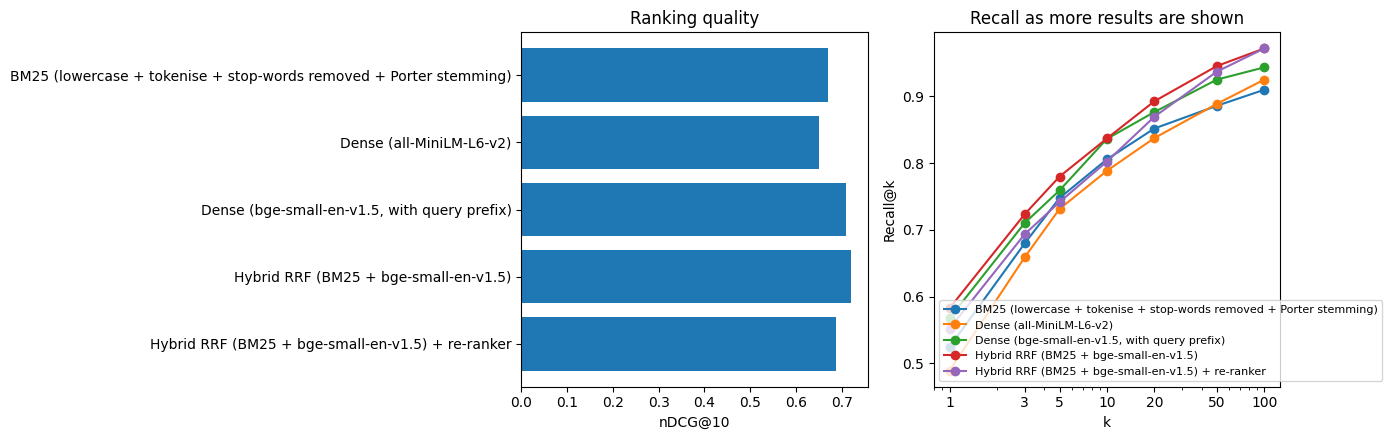

In [ ]:
from sps.evaluate import query_metrics
keys = list(main.index)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].barh([RESULTS[k]["method"] for k in keys][::-1], [RESULTS[k]["nDCG@10"] for k in keys][::-1], color="C0")
ax[0].set_xlabel("nDCG@10"); ax[0].set_title("Ranking quality")
ks = [1, 3, 5, 10, 20, 50, 100]
for k_ in keys:
    rec = [np.mean([query_metrics(RUNS[k_][q], corpus.qrels[q], ks=(kk,))[f"Recall@{kk}"] for q in corpus.qrels]) for kk in ks]
    ax[1].plot(ks, rec, marker="o", label=RESULTS[k_]["method"])
ax[1].set_xscale("log"); ax[1].set_xticks(ks); ax[1].set_xticklabels(ks)
ax[1].set_xlabel("k"); ax[1].set_ylabel("Recall@k"); ax[1].set_title("Recall as more results are shown"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("results/main_results.png", dpi=150); plt.show()

## 7. Error analysis
**What this does:** compares BM25 and the best dense model **query by query** (nDCG@10), then shows the queries where each wins clearly, with the relevant abstract and what each method returned instead. Use these examples in the Discussion: look for patterns such as exact technical terms or gene/drug names (often favour BM25) versus paraphrases and synonyms (often favour dense retrieval).

It also groups queries by **word overlap** with their relevant abstract (share of the query's content words that appear in it). This tests the hypothesis that keyword search depends on shared vocabulary while semantic search does not.

In [ ]:
dense_key = "dense_bge" if best_dense is bge else "dense_minilm"
pq_b = per_query_scores(RUNS["bm25"], corpus.qrels); pq_d = per_query_scores(RUNS[dense_key], corpus.qrels)
pq_h = per_query_scores(RUNS["hybrid_rrf"], corpus.qrels)
pre = BM25Preprocessor(True, True)

rows = []
for q in corpus.qrels:
    rel_ids = [d for d, g in corpus.qrels[q].items() if g > 0]
    q_terms = set(pre(corpus.queries[q]))
    doc_terms = set().union(*[set(pre(texts[idx[d]])) for d in rel_ids if d in idx])
    rows.append({"qid": q, "query": corpus.queries[q],
                 "BM25": pq_b[q]["nDCG@10"], "Dense": pq_d[q]["nDCG@10"], "Hybrid": pq_h[q]["nDCG@10"],
                 "overlap": len(q_terms & doc_terms) / max(len(q_terms), 1)})
pq = pd.DataFrame(rows).set_index("qid")
pq["dense - bm25"] = pq["Dense"] - pq["BM25"]

print("Queries where dense wins:", (pq["dense - bm25"] > 0).sum(), "| BM25 wins:", (pq["dense - bm25"] < 0).sum(),
      "| tie:", (pq["dense - bm25"] == 0).sum())
pq["overlap band"] = pd.qcut(pq["overlap"].rank(method="first"), 3, labels=["low overlap", "medium", "high overlap"])
display(pq.groupby("overlap band", observed=True)[["BM25", "Dense", "Hybrid"]].mean().style.format("{:.3f}")
        .set_caption("Mean nDCG@10 by query-document word overlap"))
pq.to_csv("results/per_query.csv")

Queries where dense wins: 77 | BM25 wins: 55 | tie: 168


,BM25,Dense,Hybrid
overlap band,,,
low overlap,0.335,0.461,0.426
medium,0.752,0.762,0.796
high overlap,0.924,0.907,0.940


In [ ]:
def show(q, n=3):
    print("QUERY:", corpus.queries[q])
    for d in corpus.qrels[q]:
        print("  RELEVANT :", corpus.titles[idx[d]][:110])
    for name, key in [("BM25", "bm25"), ("Dense", dense_key)]:
        top = RUNS[key][q][:n]
        marks = ["✓" if d in corpus.qrels[q] else "✗" for d in top]
        print(f"  {name:6s} top{n}:", " | ".join(f"{m} {corpus.titles[idx[d]][:45]}" for m, d in zip(marks, top)))
    print()

print("=== Dense clearly better ===\n")
for q in pq.sort_values("dense - bm25", ascending=False).index[:5]: show(q)
print("=== BM25 clearly better ===\n")
for q in pq.sort_values("dense - bm25").index[:5]: show(q)

=== Dense clearly better ===

QUERY: High dietary calcium intakes are unnecessary for prevention of secondary hyperparathyroidism in subjects with 25(OH)D levels above 75 nmol/liter.
  RELEVANT : Relationship between serum parathyroid hormone levels, vitamin D sufficiency, and calcium intake.
  BM25   top3: ✗ Genetic and environmental determinants of 25- | ✗ Estimation of the dietary requirement for vit | ✗ Estimation of optimal serum concentrations of
  Dense  top3: ✓ Relationship between serum parathyroid hormon | ✗ Calcium and peak bone mass. | ✗ Calcium absorption varies within the referenc

QUERY: Infection of human T-cell lymphotropic virus type 1 is most frequent in individuals of African origin.
  RELEVANT : HTLV-I/II associated disease in England and Wales, 1993-7: retrospective review of serology requests.
  BM25   top3: ✗ The role of the immune response during SIVagm | ✗ Modulation of cellular and viral promoters by | ✗ Isolation and partial characterization of an 
  Dense  

In [ ]:
import importlib, sps.generate
importlib.reload(sps.generate)

<module 'sps.generate' from '/content/project/task2-semantic-search/src/sps/generate.py'>

## 8. *Optional:* cited answer generation
**What this does:** for a sample of queries, a small open LLM (**Qwen2.5-1.5B-Instruct**, runs on a free T4) reads the top 3 retrieved abstracts and writes a 2–4 sentence answer, citing a passage after every sentence. If the best retrieval score is low, it refuses ("Not enough evidence...") instead of guessing.

**How it is evaluated:** answers are written to `results/answers_to_check.csv`. **You** open it and fill two columns for each row (1 = yes, 0 = no):
- `faithful`: every statement is supported by the cited abstract(s);
- `citations_correct`: the citation numbers point to the right abstracts.

The `cited_passages` column contains the full text of the abstracts the model was given, so you can check each answer against them. If the answer is the refusal *"Not enough evidence..."*, put `1` in `faithful` (it invented nothing) and leave `citations_correct` empty.

Then upload the file back and run the summary cell. Checking about 25 answers by hand is transparent and enough for this assessment.

Skip this section if time is short; the retrieval study above is the complete core project.

In [ ]:
RUN_GENERATION = True     # set True to run (needs the T4 GPU; downloads ~3 GB)

if RUN_GENERATION:
    from sps.generate import CitedAnswerGenerator, answer_with_guardrail
    gen = CitedAnswerGenerator("Qwen/Qwen2.5-1.5B-Instruct")
    MIN_SCORE = float(np.percentile([bge.search(corpus.queries[q], 1)[0][1] for q in corpus.queries], 10))
    print(f"Guardrail threshold (10th percentile of top-1 cosine): {MIN_SCORE:.3f}")
    sample_q = random.Random(42).sample(list(corpus.queries), 25)
    rows = []
    for q in sample_q:
        res = bge.search(corpus.queries[q], 5)
        text, used = answer_with_guardrail(gen, corpus.queries[q], res, corpus, MIN_SCORE)
        rows.append({"qid": q, "query": corpus.queries[q], "answer": text,
                     "cited_titles": " || ".join(f"[{n}] {corpus.titles[i]}" for n, i in enumerate(used, 1)),
                     "cited_passages": "\n\n".join(f"[{n}] {corpus.titles[i]}. {corpus.texts[i]}" for n, i in enumerate(used, 1)),
                     "relevant_in_context": any(corpus.doc_ids[i] in corpus.qrels[q] for i in used),
                     "faithful": "", "citations_correct": ""})
    answers = pd.DataFrame(rows)
    answers.to_csv("results/answers_to_check.csv", index=False)
    display(answers.head(3))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Guardrail threshold (10th percentile of top-1 cosine): 0.724


,qid,query,answer,cited_titles,cited_passages,relevant_in_context,faithful,citations_correct
0,248,Chenodeosycholic acid treatment increases whole-body energy expenditure.,Passage [1] supports this claim: treatment of 12 healthy female subjects with CDCA for 2 days resulted in increased BAT activity and whole-body energy expen...,[1] The Bile Acid Chenodeoxycholic Acid Increases Human Brown Adipose Tissue Activity. || [2] Metabolic effects of isoenergetic nutrient exchange over 24 ho...,[1] The Bile Acid Chenodeoxycholic Acid Increases Human Brown Adipose Tissue Activity.. The interest in brown adipose tissue (BAT) as a target to combat met...,True,,
1,56,APOE4 expression in iPSC-derived neurons increases AlphaBeta production and tau phosphorylation causing GABA neuron degeneration.,"Passage [1] supports this claim: using human neurons derived from induced pluripotent stem cells that expressed apolipoprotein E4 (ApoE4), a variant of the ...",[1] Gain of toxic Apolipoprotein E4 effects in Human iPSC-Derived Neurons Is Ameliorated by a Small-Molecule Structure Corrector || [2] Induced pluripotent ...,[1] Gain of toxic Apolipoprotein E4 effects in Human iPSC-Derived Neurons Is Ameliorated by a Small-Molecule Structure Corrector. Efforts to develop drugs f...,True,,
2,649,Integrating classroom-based collaborative learning with Web-based collaborative learning leads to subpar class performance,Not enough evidence in the retrieved papers to answer this.,,,False,,


In [ ]:
# After filling in the CSV: upload it back (left sidebar -> Files) to results/answers_checked.csv, then run this cell.
path = "results/answers_checked.csv"
if os.path.exists(path):
    chk = pd.read_csv(path)
    refused = chk["answer"].str.startswith("Not enough evidence")
    print(f"Answers checked: {len(chk)}  (of which refusals: {refused.sum()})")
    print(f"Faithful (all answers):                 {chk['faithful'].mean():.0%}")
    print(f"Citations correct (non-refusals only):  {chk.loc[~refused, 'citations_correct'].mean():.0%}")
    print(f"Relevant abstract was among the 3 passages given to the model: {chk['relevant_in_context'].mean():.0%}")
else:
    print("No checked file yet.")

Answers checked: 25  (of which refusals: 5)
Faithful (all answers):                 52%
Citations correct (non-refusals only):  80%
Relevant abstract was among the 3 passages given to the model: 60%


## 9. Save results and launch the demo
`results/` now contains the tables (`all_results.csv`, `per_query.csv`) and figures for the report. Download it (right-click the folder in the Files panel, or run the next cell).

The demo cell starts the Gradio app with a public link (`--share`). Add `--answers` to enable cited answers. Stop it with the ■ button when done.

In [ ]:
!zip -qr results.zip results
from google.colab import files
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!python app.py --share